# 01 — Reproducing Deng, Liang & Gupta (2017)

Macrospin model of the elliptical perpendicular MTJ free layer of
*J. Deng, G. Liang, G. Gupta, "Ultrafast and low-energy switching in voltage-controlled elliptical pMTJ", Sci. Rep. **7**, 16562 (2017)*:
a 150 × 50 × 1.7 nm³ CoFeB ellipse with a 2 nm MgO barrier, a 50 mT in-plane bias field from the bias layer, and a trapezoidal VCMA pulse of 1.6 V.

Steps
1. demagnetization factors of the elliptic-cylinder free layer (Beleggia *et al.* 2005/2006),
2. static anisotropy and the canted zero-voltage equilibria,
3. LLG dynamics for $t_{ON}$ = 0.35, 0.70 and 1.05 ns (the paper's Fig. 2),
4. how much the result depends on the initial state (switching phase diagram).

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))   # use the repo copy without installing

import numpy as np
import matplotlib.pyplot as plt
import vcma_mtj as vm
from vcma_mtj import experiments as ex, plotting as vp
vp.apply_style(9)
DATA = pathlib.Path.cwd().parent / "data"
dev = vm.deng2017()

## 1. Demagnetization factors

The free layer is a thin **elliptic cylinder**, not an ellipsoid, so the Osborn ellipsoid formulas do not apply.
`vm.demag_factors` evaluates the exact Fourier-space expressions of Beleggia *et al.* (Eqs. 9–10 of the report).

In [2]:
N = vm.demag_factors(length=150e-9, width=50e-9, thickness=1.7e-9)
print(f"Nx = {N.Nx:.6f}\nNy = {N.Ny:.6f}\nNz = {N.Nz:.6f}\nsum = {sum(N):.12f}")

Nx = 0.012241
Ny = 0.057682
Nz = 0.930077
sum = 1.000000000000


## 2. Static anisotropy

$K_u(V) = K_{U,\mathrm{bulk}} + [K_{I0} - \xi V/t_{MgO}]/t_{FL}$ and
$K_{\mathrm{eff},xz/yz}(V) = K_u(V) - K_d (N_z - N_{x/y})$ with $K_d = \mu_0 M_s^2/2$.

In [3]:
for k, v in dev.summary().items():
    print(f"{k:26s} {v:12.5g}")

Nx                             0.012241
Ny                             0.057682
Nz                              0.93008
Ku(0) [J/m^3]                9.8097e+05
Keff(0) [J/m^3]                   57615
mu0 H_K,eff(0) [mT]               91.67
mu0 H_K,eff,xz(0) [mT]           111.01
mu0 H_K,eff,yz(0) [mT]           182.78
V_c (Keff=0) [V]                 3.9178
V_xz [V]                         4.7442
V_yz [V]                         7.8118
V_Ku=0 [V]                       66.706


With the 50 mT bias field along $x$ the two stable states are **canted** away from $\pm z$,
with $m_x = \mu_0 H_x / \mu_0 H_{K,\mathrm{eff},xz}$ (exact for a field along a principal axis):

In [4]:
bias = (50e-3, 0, 0)
m_up, m_dn = vm.equilibrium(dev, 0, bias, +1), vm.equilibrium(dev, 0, bias, -1)
print("+z state:", m_up.round(4), " -z state:", m_dn.round(4))
print(f"cant angle = {np.degrees(np.arccos(m_up[2])):.2f} deg;  analytic m_x = {50e-3/dev.BKeff_xz(0):.4f}")

+z state: [0.4504 0.     0.8928]  -z state: [ 0.4504 -0.     -0.8928]
cant angle = 26.77 deg;  analytic m_x = 0.4504


## 3. Switching versus pulse ON-time (paper Fig. 2)

Following the paper's figure, the layer starts at the pole $(0,0,-1)$; $\alpha$ = 0.01 throughout.
Eq. (8) predicts a half precession period $T/2 = \pi(1+\alpha^2)/(\gamma\mu_0H_x)$:

T/2 (Eq. 8) = 0.357 ns


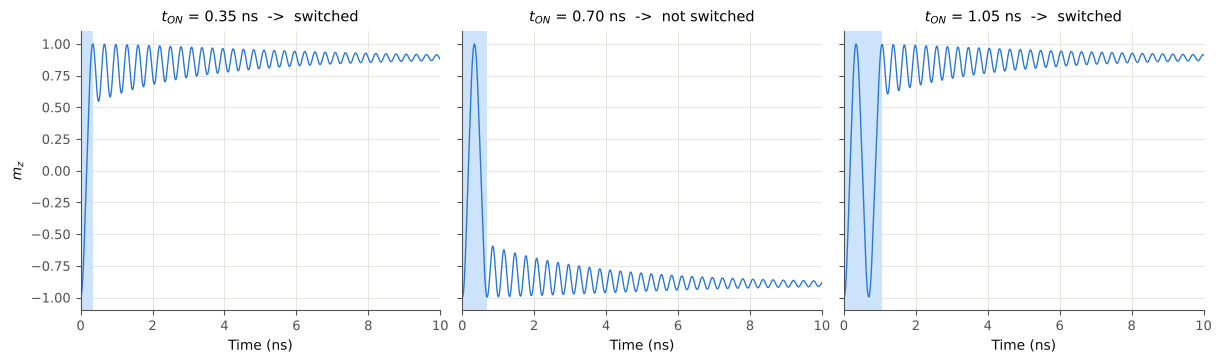

In [5]:
print(f"T/2 (Eq. 8) = {dev.period_bias_only(50e-3)/2*1e9:.3f} ns")
runs = ex.run_deng(dev)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True, layout="constrained")
for ax, (t_on, r) in zip(axes, runs.items()):
    ax.axvspan(0, t_on*1e9, color="#cde2fb", lw=0)
    ax.plot(r.t_ns, r.mz, color=vp.C_MX, lw=0.9)
    ax.set(title=f"$t_{{ON}}$ = {t_on*1e9:.2f} ns  ->  {'switched' if r.switched else 'not switched'}",
           xlabel="Time (ns)", xlim=(0, 10))
axes[0].set_ylabel("$m_z$");

Odd multiples of $T/2$ (0.35 and 1.05 ns) switch the layer; the even multiple (0.70 ns) returns it to the starting hemisphere — the behaviour reported by Deng *et al.*

## 4. Sensitivity to the initial state

Starting at the pole puts the magnetization 26.8° away from its real equilibrium, i.e. with extra energy.
At 1.6 V the pole is *above* the in-plane saddle, while the canted equilibrium is *below* it:

In [6]:
for name, m in (("pole (0,0,1)", [0, 0, 1]), ("canted equilibrium", m_up)):
    print(f"E({name:18s}, 1.6 V) = {vm.energy_density(dev, m, 1.6, bias)/1e3:7.2f} kJ/m^3")
print(f"E(in-plane saddle +x,   1.6 V) = {vm.energy_density(dev, [1, 0, 0], 1.6, bias)/1e3:7.2f} kJ/m^3")

E(pole (0,0,1)      , 1.6 V) =  -34.09 kJ/m^3
E(canted equilibrium, 1.6 V) =  -53.01 kJ/m^3
E(in-plane saddle +x,   1.6 V) =  -50.70 kJ/m^3


The full switching phase diagram (final $m_z$ versus pulse amplitude and ON-time) makes the difference visible.
It is loaded from `data/phase_diagram_50mT.npz` (written by `scripts/make_figures.py`); set `RECOMPUTE = True` to rerun a coarse version here.

lowest amplitude that switches from the canted equilibrium: 1.84 V


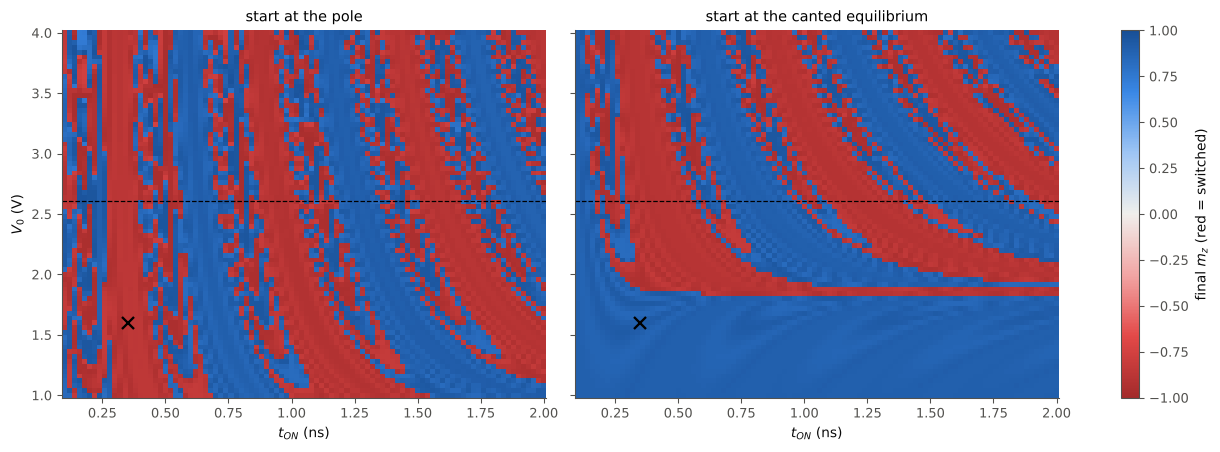

In [7]:
RECOMPUTE = False
path = DATA / "phase_diagram_50mT.npz"
if path.exists() and not RECOMPUTE:
    d = np.load(path); Vs, tons, maps = d["V"], d["t_on"], {"pole": d["mz_pole"], "eq": d["mz_eq"]}
else:
    Vs, tons = np.arange(1.0, 4.01, 0.1), np.arange(0.1e-9, 2.01e-9, 0.05e-9)
    maps = {"pole": ex.switching_map(dev, Vs, tons, bias, [0, 0, 1]),
            "eq": ex.switching_map(dev, Vs, tons, bias, m_up)}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
for ax, key, title in zip(axes, ("pole", "eq"), ("start at the pole", "start at the canted equilibrium")):
    pc = ax.pcolormesh(tons*1e9, Vs, maps[key], cmap=vp.MZ_CMAP, norm=vp.mz_norm(), shading="nearest")
    ax.plot(0.35, 1.6, "kx", ms=8, mew=1.5)
    ax.axhline(dev.V_crit_for_bias(50e-3), color="k", lw=0.8, ls="--")
    ax.set(title=title, xlabel="$t_{ON}$ (ns)"); ax.grid(False)
axes[0].set_ylabel("$V_0$ (V)")
fig.colorbar(pc, ax=axes, label="final $m_z$ (red = switched)")
sw = maps["eq"] < 0
print(f"lowest amplitude that switches from the canted equilibrium: {Vs[np.where(sw.any(axis=1))[0][0]]:.2f} V")

**Take-away.** In this macrospin model the paper's 1.6 V / 0.35 ns operating point reproduces Fig. 2 only when the free layer starts at the pole.
From the true canted equilibrium a 1.6 V pulse produces small-angle precession around the new equilibrium, and switching needs $V_0 \gtrsim 1.84$ V —
still below the 2.61 V at which the 50 mT field removes the static barrier, because the pulse-induced jump of the equilibrium pumps energy into the precession.
Thermal fluctuations, the reference-layer stray field and STT (all omitted here) would modify these thresholds.